<a href="https://colab.research.google.com/github/santhwana27/Machine-Learning-Lab-Programs/blob/main/PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


========== TASK 1: LOAD DATASET ==========


Saving PCA_Lab_Dataset_FINAL.xlsx to PCA_Lab_Dataset_FINAL (3).xlsx


,Record_ID,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Category
0,1,69.394,41.410,92.474,0.68929,249.600,72.812,Class_3
1,2,57.517,39.418,117.805,0.46986,201.941,89.406,Class_2
2,3,25.073,15.761,100.371,0.33674,150.365,67.317,Class_1
3,4,58.366,47.963,156.155,0.41419,177.654,107.031,Class_2
4,5,32.593,21.135,103.053,0.34925,160.427,70.200,Class_1
5,6,49.044,31.771,114.819,0.47169,190.987,82.877,Class_2
6,7,63.622,37.318,95.499,0.60597,232.762,77.421,Class_3
7,8,50.506,39.531,122.114,0.42179,190.326,90.358,Class_2
8,9,34.448,18.576,97.578,0.36463,169.289,67.096,Class_1
9,10,66.558,44.519,97.723,0.66130,249.348,79.195,Class_3


Shape: (600, 8) 
Category distribution:
 Category
Class_3    200
Class_2    200
Class_1    200
Name: count, dtype: int64


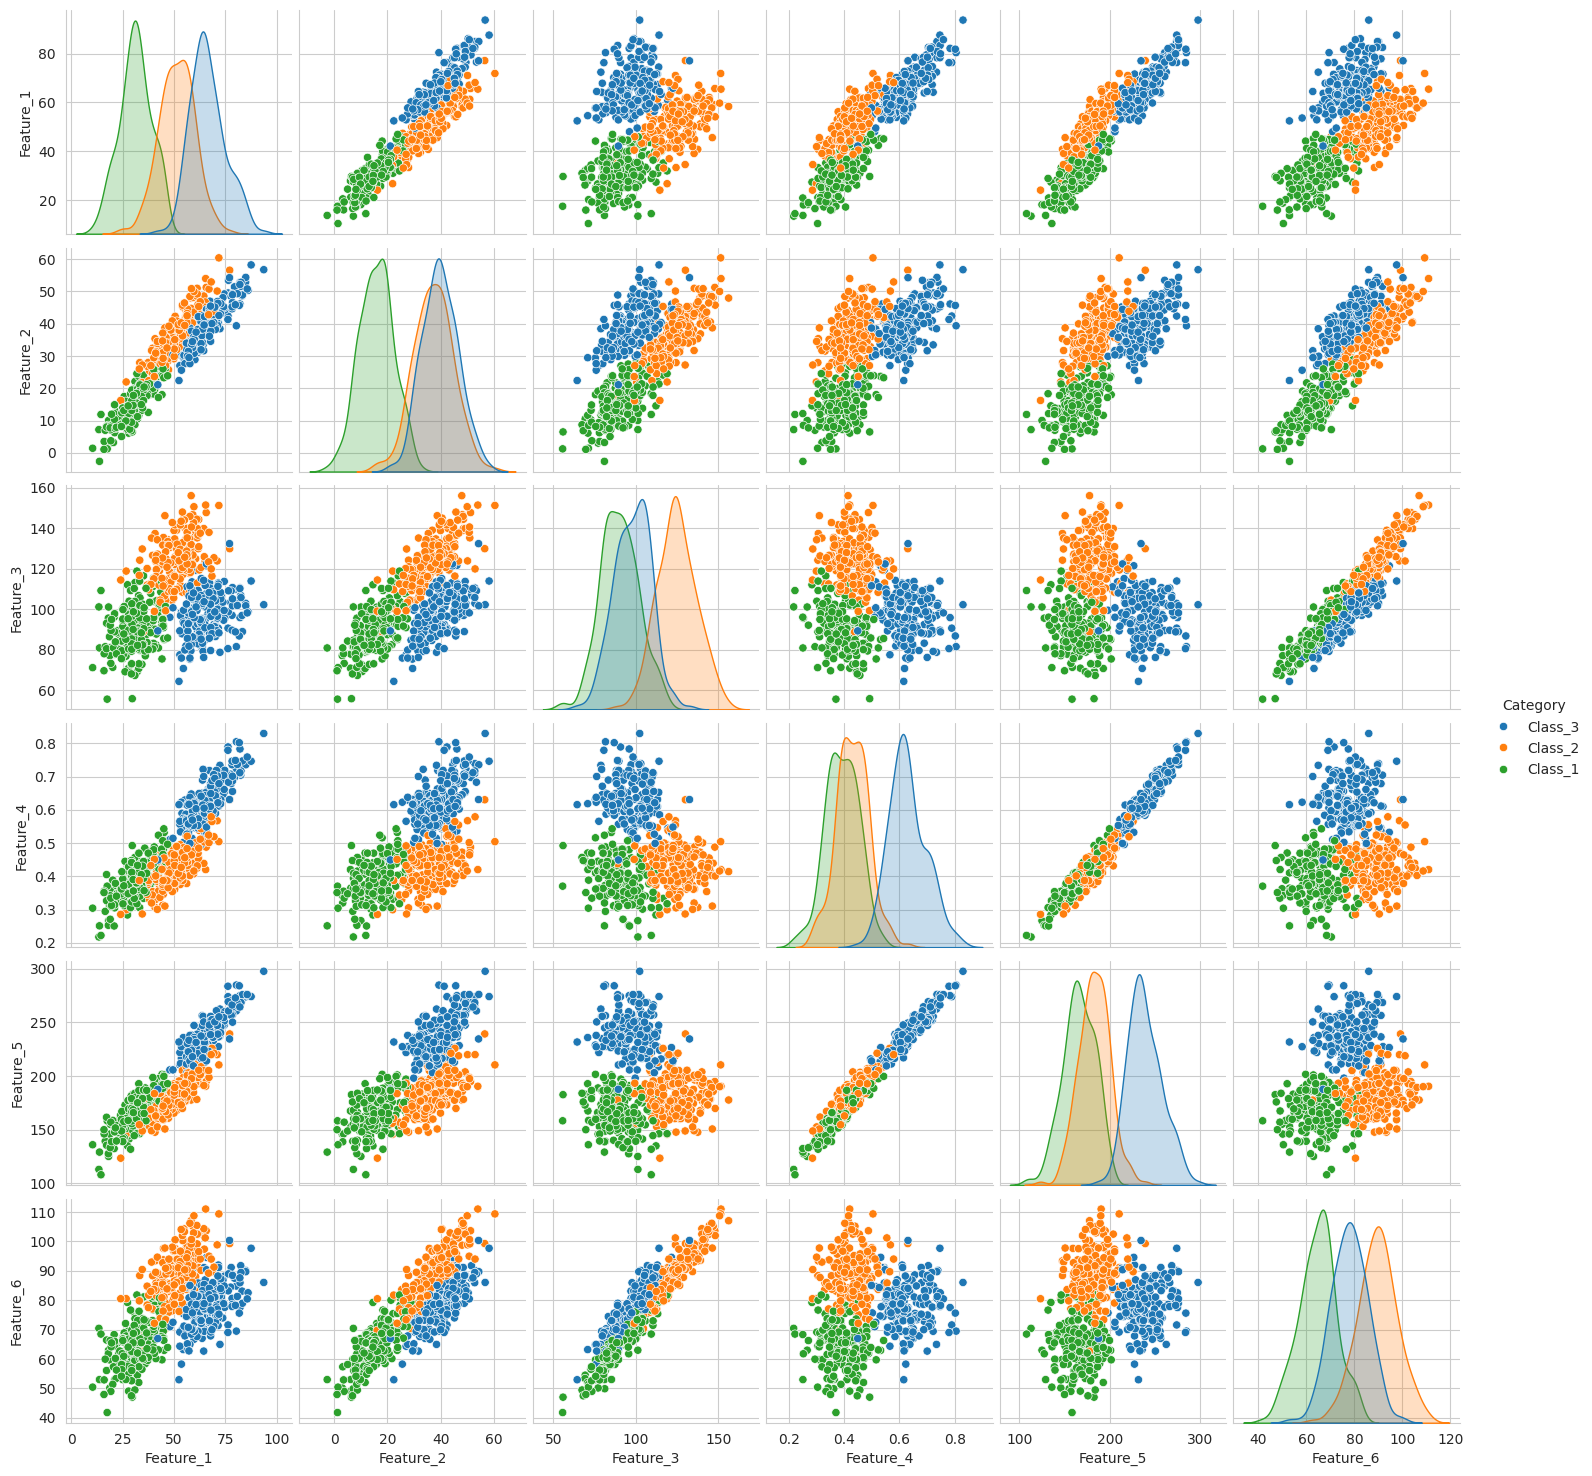


========== TASK 2: STANDARDIZATION ==========
Means: [-0. -0. -0.  0.  0.  0.]
Standard deviations: [1. 1. 1. 1. 1. 1.]


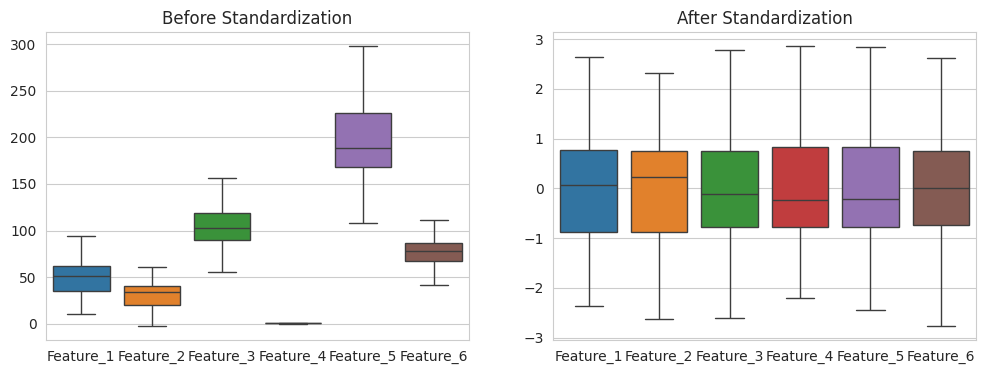


========== TASK 3: COVARIANCE MATRIX ==========


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6
Feature_1,1.002,0.925,0.307,0.863,0.908,0.578
Feature_2,0.925,1.002,0.621,0.635,0.704,0.823
Feature_3,0.307,0.621,1.002,-0.182,-0.098,0.933
Feature_4,0.863,0.635,-0.182,1.002,0.983,0.124
Feature_5,0.908,0.704,-0.098,0.983,1.002,0.210
Feature_6,0.578,0.823,0.933,0.124,0.210,1.002


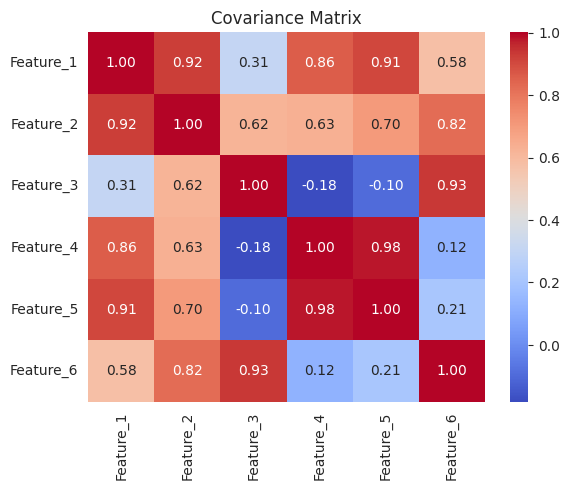


========== TASK 4: EIGENVALUES & VARIANCE ==========


,PC1,PC2,PC3,PC4,PC5,PC6
Feature_1,-0.496,-0.114,-0.246,0.153,-0.516,-0.625
Feature_2,-0.491,0.141,-0.383,0.287,0.714,-0.005
Feature_3,-0.231,0.624,-0.343,-0.559,-0.240,0.266
Feature_4,-0.394,-0.434,0.320,-0.687,0.261,-0.119
Feature_5,-0.421,-0.383,-0.015,0.233,-0.311,0.724
Feature_6,-0.356,0.493,0.757,0.237,-0.032,-0.021


,Eigenvalue,Explained %,Cumulative %
PC1,3.934,65.457,65.457
PC2,2.012,33.470,98.926
PC3,0.023,0.378,99.304
PC4,0.019,0.324,99.629
PC5,0.012,0.207,99.836
PC6,0.010,0.164,100.000


Components for 95% variance: 2

========== TASK 5: TWO-COMPONENT PCA ==========


,PC1,PC2
0,2.022232,-1.896653
1,1.089037,0.938790
2,-2.654964,0.497729
3,1.937907,3.441476
4,-1.951997,0.553563
5,0.201636,0.672490
6,1.388372,-1.146558
7,0.671019,1.464439
8,-1.994607,0.061120
9,2.204809,-1.320042


Manual variance: [0.65456548 0.33469651]
Sklearn variance: [0.65456548 0.33469651]

========== TASK 6: PCA SCATTER PLOT ==========


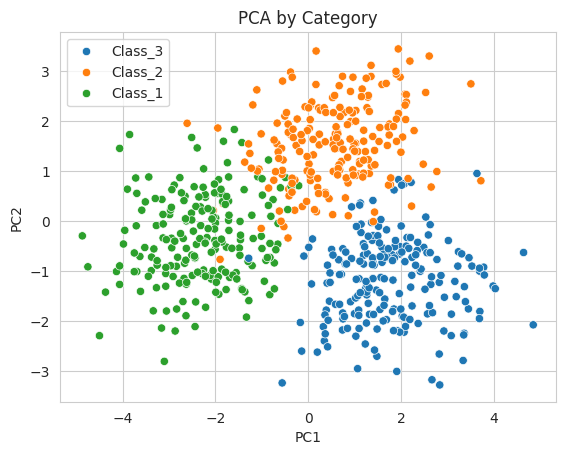


========== TASK 7: PCA LOADINGS & BIPLOT ==========


,PC1,PC2
Feature_1,0.496,-0.114
Feature_2,0.491,0.141
Feature_3,0.231,0.624
Feature_4,0.394,-0.434
Feature_5,0.421,-0.383
Feature_6,0.356,0.493


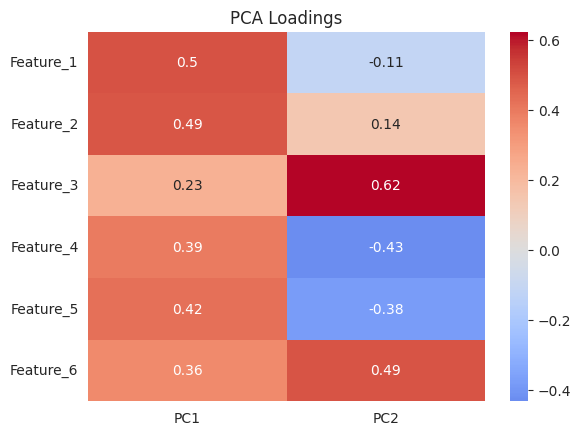

PC1 contributions:
 Feature_1    0.495709
Feature_2    0.491473
Feature_5    0.421360
Feature_4    0.394134
Feature_6    0.355890
Feature_3    0.230615
Name: PC1, dtype: float64
PC2 contributions:
 Feature_3    0.623617
Feature_6    0.493193
Feature_4    0.433522
Feature_5    0.383461
Feature_2    0.141288
Feature_1    0.113647
Name: PC2, dtype: float64


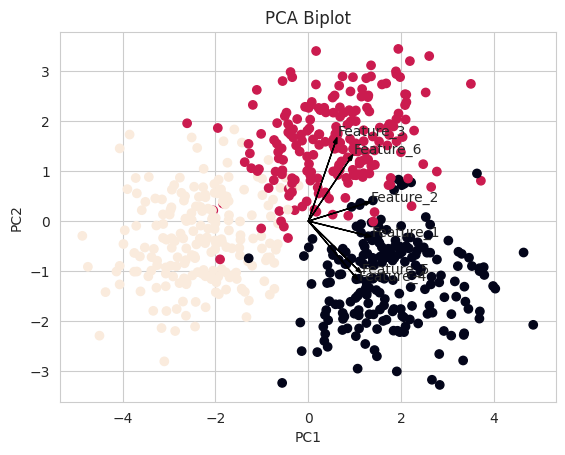


========== TASK 8: DATA RECONSTRUCTION ==========


,Original,Reconstructed
Feature_1,69.394,69.887
Feature_2,41.410,40.197
Feature_3,92.474,90.778
Feature_4,0.689,0.680
Feature_5,249.600,252.474
Feature_6,72.812,74.632


Reconstruction MSE: 0.01073801224036837

========== TASK 9: RECONSTRUCTION ERROR ==========


,Components,MSE
0,1,3.454345e-01
1,2,1.073801e-02
2,3,6.956739e-03
3,4,3.714297e-03
4,5,1.640473e-03
5,6,1.951245e-31


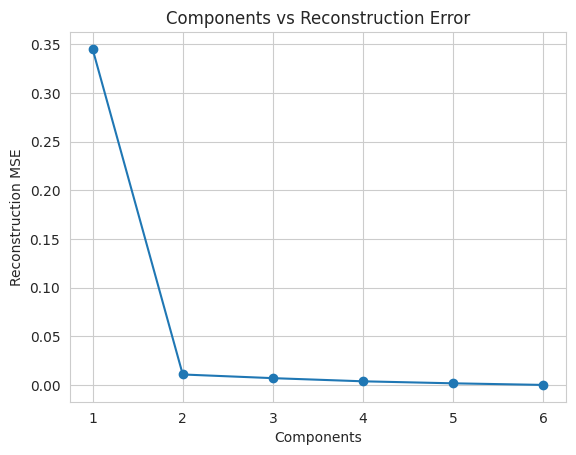


========== TASK 10: KNN CLASSIFICATION ==========


,Method,Accuracy (%)
0,Original 6 Features,95.56
1,PCA 2 Components,93.89


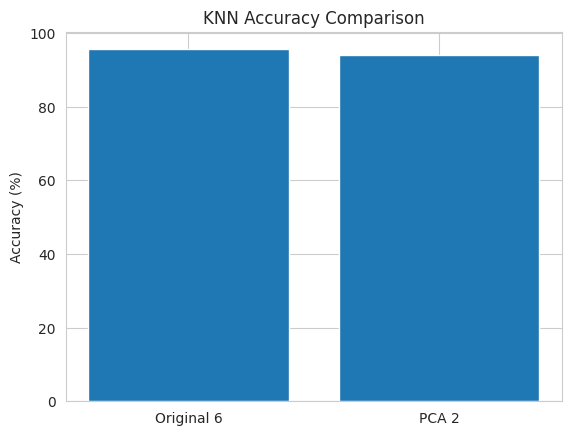


========== TASK 11: SUMMARY & CONCLUSION ==========
Features reduced: 6 to 2
Variance retained: 98.93%
Two-component reconstruction MSE: 0.010738
Original-feature KNN accuracy: 95.56%
PCA-feature KNN accuracy: 93.89%
Conclusion: PCA reduces dimensions while retaining important information.


In [ ]:

# PCA LAB - ALL 11 TASKS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# TASK 1: LOAD DATASET
print("\n========== TASK 1: LOAD DATASET ==========")
f = files.upload()
df = pd.read_excel(next(iter(f)))
features = [f'Feature_{i}' for i in range(1, 7)]
df = df.dropna(subset=features + ['Category'])
X, y = df[features], df['Category']
display(df.head(10))
print("Shape:", df.shape, "\nCategory distribution:\n", y.value_counts())
sns.pairplot(df, vars=features, hue='Category')
plt.show()

# TASK 2: STANDARDIZATION
print("\n========== TASK 2: STANDARDIZATION ==========")
scaler = StandardScaler()
Z = scaler.fit_transform(X)
print("Means:", Z.mean(0).round(3))
print("Standard deviations:", Z.std(0).round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=X, ax=ax[0])
sns.boxplot(data=pd.DataFrame(Z, columns=features), ax=ax[1])
ax[0].set_title("Before Standardization")
ax[1].set_title("After Standardization")
plt.show()

# TASK 3: COVARIANCE MATRIX
print("\n========== TASK 3: COVARIANCE MATRIX ==========")
cov = np.cov(Z, rowvar=False)
display(pd.DataFrame(cov, index=features, columns=features).round(3))
sns.heatmap(cov, annot=True, fmt='.2f', cmap='coolwarm',
            xticklabels=features, yticklabels=features)
plt.title("Covariance Matrix")
plt.show()

# TASK 4: EIGENVALUES AND VARIANCE
print("\n========== TASK 4: EIGENVALUES & VARIANCE ==========")
eigval, eigvec = np.linalg.eigh(cov)
idx = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[idx], eigvec[:, idx]
var = eigval / eigval.sum()
display(pd.DataFrame(eigvec, index=features,
                     columns=[f'PC{i}' for i in range(1, 7)]).round(3))
display(pd.DataFrame({
    'Eigenvalue': eigval, 'Explained %': var * 100,
    'Cumulative %': np.cumsum(var) * 100
}, index=[f'PC{i}' for i in range(1, 7)]).round(3))
print("Components for 95% variance:", np.argmax(np.cumsum(var) >= .95) + 1)

# TASK 5: TWO-COMPONENT PCA
print("\n========== TASK 5: TWO-COMPONENT PCA ==========")
pca = PCA(2)
P = pca.fit_transform(Z)
display(pd.DataFrame(P[:10], columns=['PC1', 'PC2']))
print("Manual variance:", var[:2])
print("Sklearn variance:", pca.explained_variance_ratio_)

# TASK 6: PCA SCATTER PLOT
print("\n========== TASK 6: PCA SCATTER PLOT ==========")
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=y.to_numpy())
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA by Category")
plt.show()

# TASK 7: LOADINGS AND BIPLOT
print("\n========== TASK 7: PCA LOADINGS & BIPLOT ==========")
load = pd.DataFrame(pca.components_.T, index=features,
                    columns=['PC1', 'PC2'])
display(load.round(3))
sns.heatmap(load, annot=True, cmap='coolwarm', center=0)
plt.title("PCA Loadings")
plt.show()
print("PC1 contributions:\n", load.PC1.abs().sort_values(ascending=False))
print("PC2 contributions:\n", load.PC2.abs().sort_values(ascending=False))
plt.scatter(P[:, 0], P[:, 1], c=pd.factorize(y)[0])
for i, name in enumerate(features):
    dx, dy = pca.components_[:, i] * 2.5
    plt.arrow(0, 0, dx, dy, head_width=.08, color='black')
    plt.text(dx * 1.1, dy * 1.1, name)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA Biplot")
plt.show()

# TASK 8: DATA RECONSTRUCTION
print("\n========== TASK 8: DATA RECONSTRUCTION ==========")
rec2 = pca.inverse_transform(P)
R = scaler.inverse_transform(rec2)
display(pd.DataFrame({'Original': X.iloc[0], 'Reconstructed': R[0]},
                     index=features).round(3))
print("Reconstruction MSE:", np.mean((Z - rec2) ** 2))

# TASK 9: RECONSTRUCTION ERROR
print("\n========== TASK 9: RECONSTRUCTION ERROR ==========")
errors = []
for n in range(1, 7):
    m = PCA(n)
    errors.append(np.mean((Z - m.inverse_transform(m.fit_transform(Z))) ** 2))
display(pd.DataFrame({'Components': range(1, 7), 'MSE': errors}))
plt.plot(range(1, 7), errors, marker='o')
plt.xlabel("Components"); plt.ylabel("Reconstruction MSE")
plt.title("Components vs Reconstruction Error")
plt.xticks(range(1, 7))
plt.show()

# TASK 10: KNN CLASSIFICATION
print("\n========== TASK 10: KNN CLASSIFICATION ==========")
Xt, Xv, yt, yv = train_test_split(
    X, y, test_size=.3, random_state=42, stratify=y)
models = [
    make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    make_pipeline(StandardScaler(), PCA(2), KNeighborsClassifier(5))
]
acc = []
for m in models:
    m.fit(Xt, yt)
    acc.append(accuracy_score(yv, m.predict(Xv)) * 100)
display(pd.DataFrame({
    'Method': ['Original 6 Features', 'PCA 2 Components'],
    'Accuracy (%)': acc
}).round(2))
plt.bar(['Original 6', 'PCA 2'], acc)
plt.ylabel("Accuracy (%)")
plt.title("KNN Accuracy Comparison")
plt.show()

# TASK 11: SUMMARY AND CONCLUSION
print("\n========== TASK 11: SUMMARY & CONCLUSION ==========")
print(f"Features reduced: 6 to 2")
print(f"Variance retained: {pca.explained_variance_ratio_.sum()*100:.2f}%")
print(f"Two-component reconstruction MSE: {errors[1]:.6f}")
print(f"Original-feature KNN accuracy: {acc[0]:.2f}%")
print(f"PCA-feature KNN accuracy: {acc[1]:.2f}%")
print("Conclusion: PCA reduces dimensions while retaining important information.")
